# 02 eda
Dataset-dependent analysis is pending. No dataset is loaded automatically.

In [2]:
from pathlib import Path
import pandas as pd
from classification.plotting import save_figure
DATA_DIR = Path("/workspace/data/raw")
df = pd.read_csv(Path(DATA_DIR) / "student_mental_health.csv")

## Target counts, proportions, and imbalance

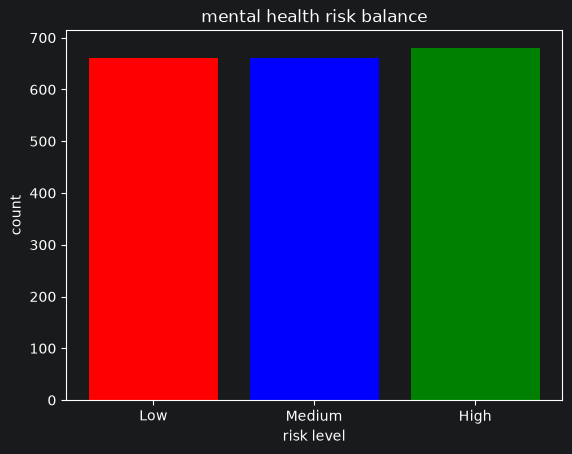

In [21]:
import matplotlib.pyplot as plt

counts = df["Mental_Health_Risk"].value_counts().reindex(["Low", "Medium", "High"])
plt.bar(counts.index, counts.values, color = ["red", "blue", "green"])
plt.title("mental health risk balance")
plt.xlabel("risk level")
plt.ylabel("count")
save_figure(plt.gcf(), "mental_health_risk_distribution")
plt.show()


## Numerical distributions and outliers
Record observations and justify decisions here after selecting the dataset.

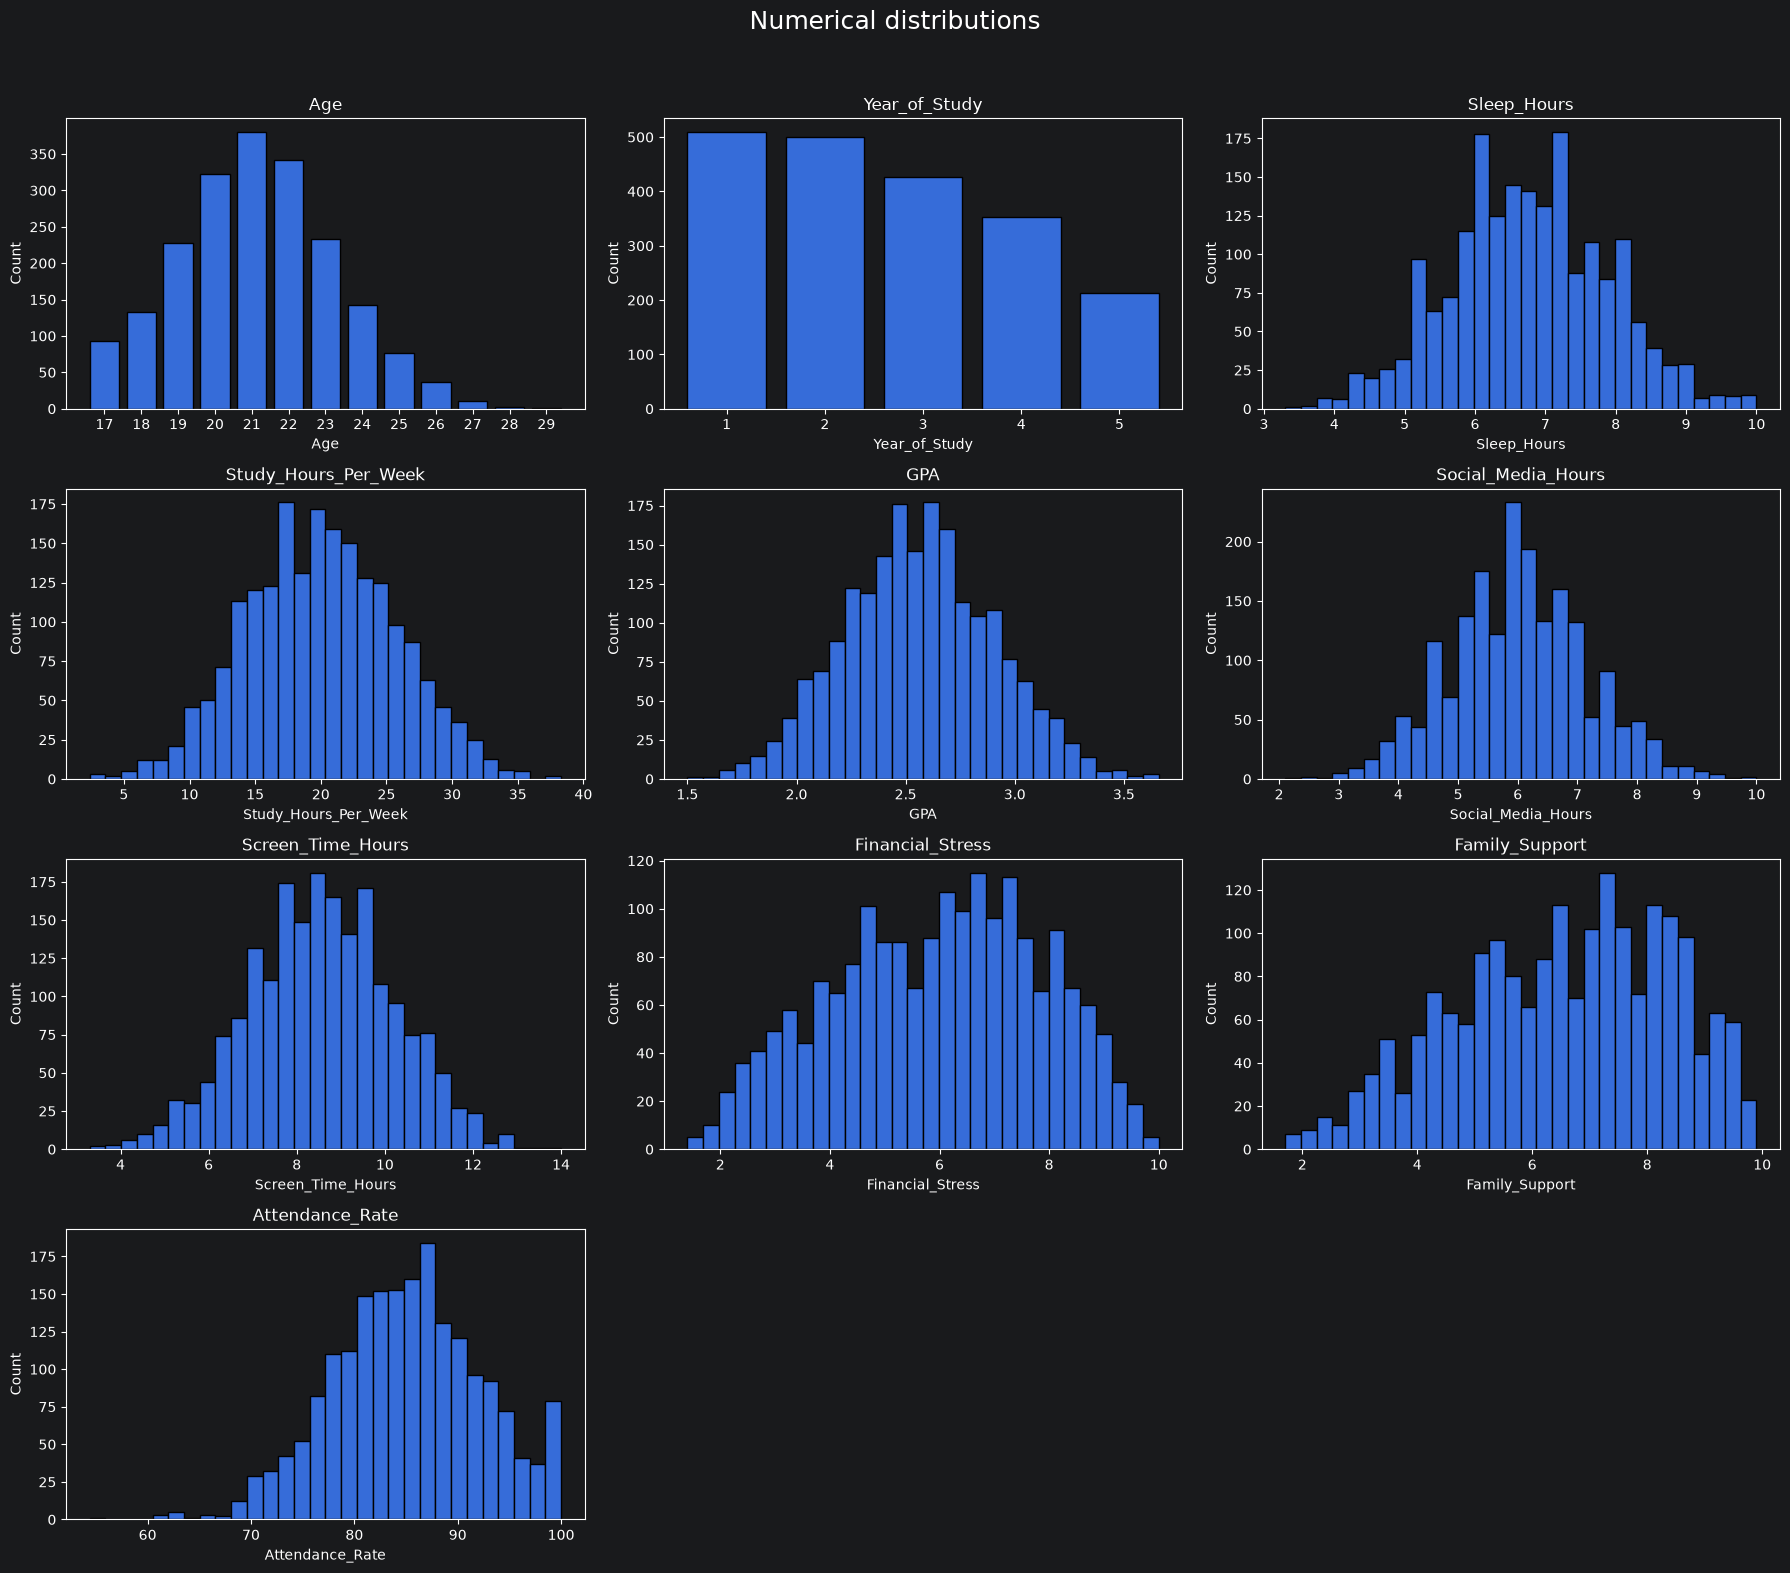

In [52]:
import matplotlib.pyplot as plt

numerical_columns = df.select_dtypes(include="number").columns


fig, axes = plt.subplots(4, 3, figsize=(18, 4 * 4), squeeze=False)
fig.suptitle("Numerical distributions", fontsize=18)
1
for i, column in enumerate(numerical_columns):
    ax = axes.flat[i]
    if column in ["Age", "Year_of_Study"]:
        counts = df[column].value_counts().sort_index()
        ax.bar(counts.index, counts.values, edgecolor="black")
        ax.set_xticks(counts.index)
    else:
        ax.hist(df[column].dropna(), bins=30, edgecolor="black")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

for i in range(len(numerical_columns), 4 * 3):
    fig.delaxes(axes.flat[i])

fig.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, "numerical_distributions")
plt.show()


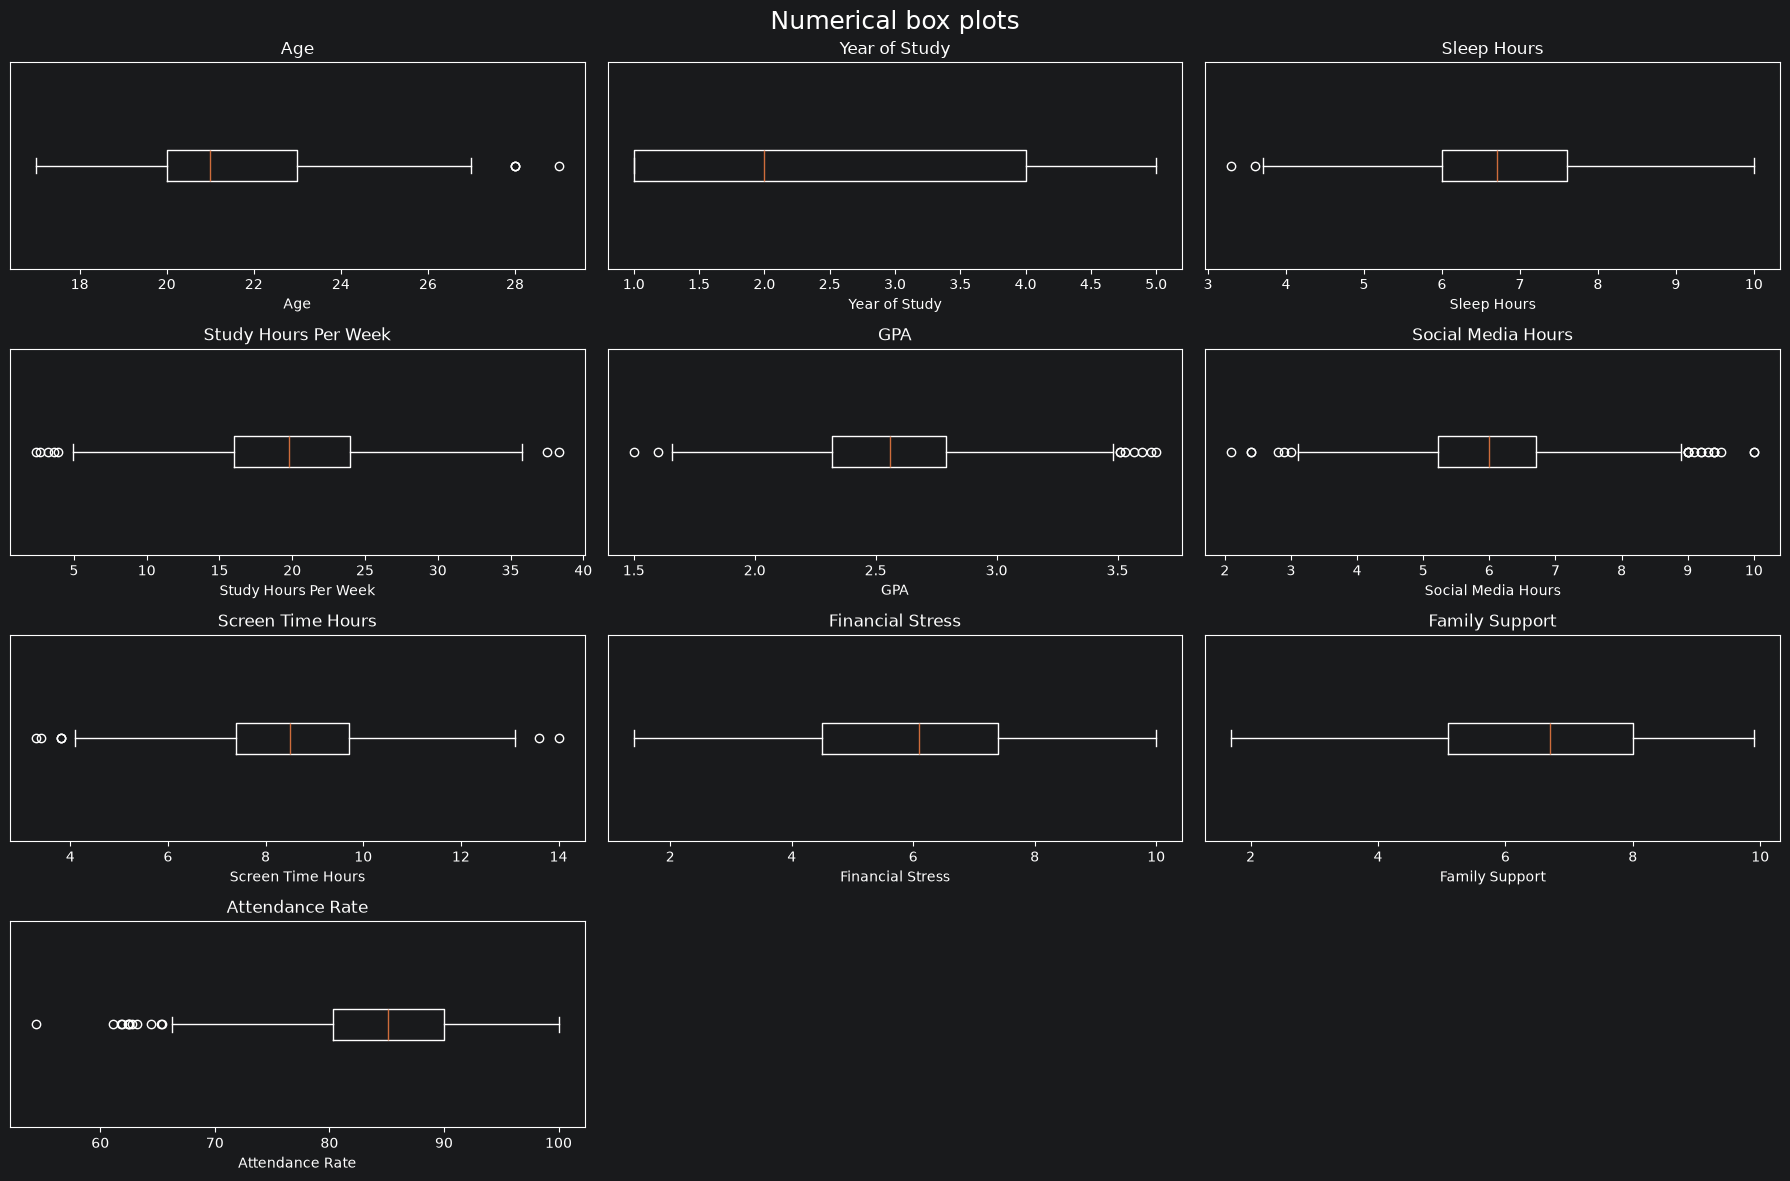

In [53]:
numerical_columns = df.select_dtypes(include="number").columns


fig, axes = plt.subplots(4, 3, figsize=(18, 3 * 4), squeeze=False)
fig.suptitle("Numerical box plots", fontsize=18)

for i, column in enumerate(numerical_columns):
    ax = axes.flat[i]
    ax.boxplot(df[column].dropna(), orientation="horizontal")
    ax.set_title(column.replace("_", " "))
    ax.set_xlabel(column.replace("_", " "))
    ax.set_yticks([])

for i in range(len(numerical_columns), 4 * 3):
    fig.delaxes(axes.flat[i])

fig.tight_layout()
save_figure(fig, "numerical_boxplots")
plt.show()


In [83]:
contradiction = df["Social_Media_Hours"] > df["Screen_Time_Hours"]

display(
    df.loc[
        contradiction,
        ["Student_ID", "Social_Media_Hours", "Screen_Time_Hours"]
    ]
)

,Student_ID,Social_Media_Hours,Screen_Time_Hours
78,STU0079,5.0,4.9
168,STU0169,5.6,5.3
209,STU0210,7.5,7.3
278,STU0279,6.0,5.1
382,STU0383,5.3,4.1
424,STU0425,5.5,4.4
476,STU0477,5.5,5.3
505,STU0506,5.6,5.5
557,STU0558,4.6,4.4
588,STU0589,5.7,5.3


### Analysis of the numerical distributions and box plots

These observations describe the shapes visible in the bar plots, histograms, and box plots. Values read from the axes are approximate. In each box plot, the box spans the middle 50% of the recorded data, the line inside it marks the median, and circles beyond the whiskers indicate potential outliers under the 1.5 × IQR rule.

**Age:** The bar plot has a clear peak around **21 years**, with most observations concentrated between approximately **19 and 23 years**. Counts become smaller as we move away from this central group. The tail extends farther toward older ages, suggesting **slight right skewness**. The box shows the middle 50% between approximately **20 and 23 years**, with a median near **21**. The box plot flags ages around **28–29** as potential IQR outliers; these are unusual within the sample but still plausible student ages.

**Year_of_Study:** The tallest bars are for years **1 and 2**, followed by progressively fewer observations in years **3, 4, and 5**. The data are therefore spread across all five years but concentrated toward the earlier years, showing a **right-skewed pattern** across these ordered values. The box spans approximately years **1 to 4**, marking the middle 50% of the distribution, with the median at **2**. No observations are flagged as IQR outliers. Because academic year is discrete, the bar heights describe this distribution more clearly than the box plot alone.

**Sleep_Hours:** The histogram is broadly **bell-shaped**, with observations concentrated around **6–8 hours** and fewer observations toward the extremes. The bars are uneven, but there is **no strong visible skewness** overall. The box shows the middle 50% between approximately **6 and 7.6 hours**, with the median near **6.7 hours**. A few points around **3–4 hours** are flagged as potential IQR outliers. No unusually high sleep values are flagged in the box plot.

**Study_Hours_Per_Week:** The histogram forms a broad, approximately **symmetric mound around 20 hours**. Observations are mainly concentrated around **15–25 hours**, with frequencies decreasing toward very short and very long study durations. There is **no strong visible skewness**. The box shows the middle 50% between approximately **16 and 24 hours**, with the median near **20 hours**. Potential IQR outliers appear at both extremes: below roughly **4 hours** and above roughly **36 hours per week**.

**GPA:** The histogram is broadly **bell-shaped and approximately symmetric**, with a clear concentration around **2.5–2.6** and relatively few observations near the extremes. There is **no pronounced visible skewness**. The central box is fairly compact, placing the middle 50% between approximately **2.3 and 2.8**, with the median near **2.6**. The box plot flags a few unusually low GPAs around **1.5–1.6** and unusually high GPAs above approximately **3.5** as potential IQR outliers. These remain possible values on the GPA scale.

**Social_Media_Hours:** The histogram is concentrated around **5–7 hours per day**, with its tallest bars near **6 hours**. It has an overall **bell-shaped appearance**, although individual bar heights fluctuate. There is **no strong visible skewness**. The middle 50% lies between approximately **5.2 and 6.7 hours**, and the median is near **6 hours**. The box plot flags unusually short usage around **2–3 hours** and unusually long usage around **9–10 hours** as potential IQR outliers.

**Screen_Time_Hours:** The histogram has a broad, approximately **symmetric bell shape**, with most observations concentrated around **7–10 hours per day**. Frequencies gradually decrease toward both extremes, with **no strong visible skewness**. The box shows the middle 50% between approximately **7.4 and 9.7 hours**, and the median near **8.5 hours**. A few observations around **3–4 hours** and **13.5–14 hours** are flagged as potential IQR outliers, also there is some contradictions between screen time and social media hours , 37 rows have social media hours execute the screen time .

**Financial_Stress:** The histogram is **broadly spread across the scale**, with more observations around **5–8** than near the extremes. The tail stretches a little farther toward low stress scores, suggesting **mild left skewness**, although the overall shape is not strongly asymmetric. The middle 50% lies between approximately **4.5 and 7.4**, with the median near **6.1**. The box plot flags **no IQR outliers**. The absence of flagged points does not mean that the data have little variation; the box and whiskers still show a substantial spread.

**Family_Support:** The histogram shows a **broad concentration toward higher scores**, especially around **6–8**, while observations become less frequent toward very low support scores. The longer tail toward low values suggests **mild left skewness**. The box shows the middle 50% between approximately **5.1 and 8**, with a median near **6.7**. The median sits closer to the higher end of the box, and the whisker extends farther toward low scores, supporting this mild asymmetry. **No IQR outliers** are flagged.

**Attendance_Rate:** The histogram is concentrated around **80–95%**, with a main peak around **85–90%**. A thinner tail extends toward lower attendance, while values stop at **100%**, producing **some left asymmetry**. The box shows the middle 50% between approximately **80% and 90%**, with the median near **85%**. Several observations below roughly **66%**, including a point near **54%**, are flagged as potential IQR outliers. No high-attendance observations are flagged. These low values are unusual relative to the main concentration, but are still valid percentages.

Flagged observations should be investigated rather than removed automatically. Bell-shaped histograms suggest a shape; they do not establish that a variable follows a normal distribution.


## Categorical frequencies and rare categories
Record observations and justify decisions here after selecting the dataset.

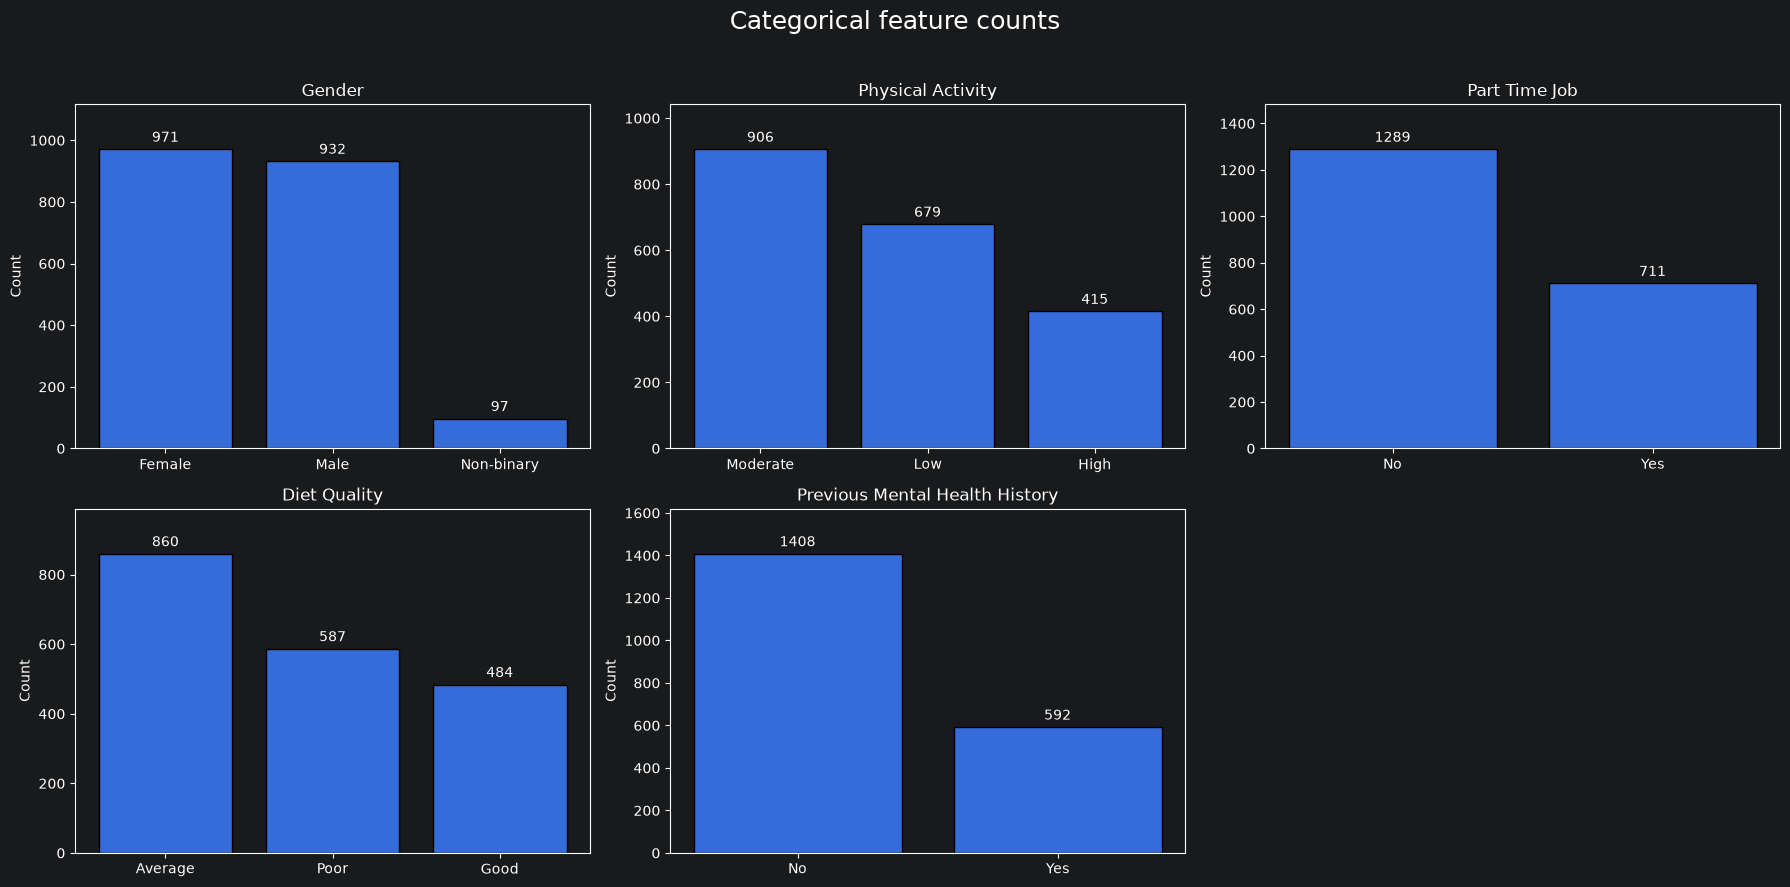

In [54]:
categorical_columns = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History",
]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle("Categorical feature counts", fontsize=18)

for i, column in enumerate(categorical_columns):
    ax = axes.flat[i]
    counts = df[column].value_counts()
    bars = ax.bar(counts.index, counts.values, edgecolor="black")
    ax.bar_label(bars, padding=3)
    ax.set_title(column.replace("_", " "))
    ax.set_ylabel("Count")
    ax.set_ylim(0, counts.max() * 1.15)

fig.delaxes(axes.flat[5])
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, "categorical_feature_counts")
plt.show()


### Analysis of categorical frequencies

**Gender:** Female and Male have similar counts, while Non-binary is much less frequent. The distribution is therefore uneven across the three categories. Non-binary is the least represented category, accounting for about 5% of records; comparisons involving this group will be based on fewer observations.

**Physical_Activity:** Moderate is the most frequent category, followed by Low, then High. The distribution is uneven, with fewer observations reporting high physical activity. Moderate is the largest category, but does not account for more than half of the records.

**Part_Time_Job:** No is more frequent than Yes, so most records indicate that the student does not have a part-time job. Both categories are substantially represented.

**Diet_Quality:** Average is the most frequent category, followed by Poor, then Good. Average is the largest group, but is not an absolute majority of recorded responses. All three categories are well represented. Missing values are excluded from these bars, so the displayed counts do not total all 2,000 rows.

**Previous_Mental_Health_History:** No is clearly more frequent than Yes, indicating that most records report no previous diagnosed mental health condition. Yes is less common but still represents a substantial group, rather than a rare category. The plot describes this synthetic dataset and does not establish real-world prevalence.


## Features versus target

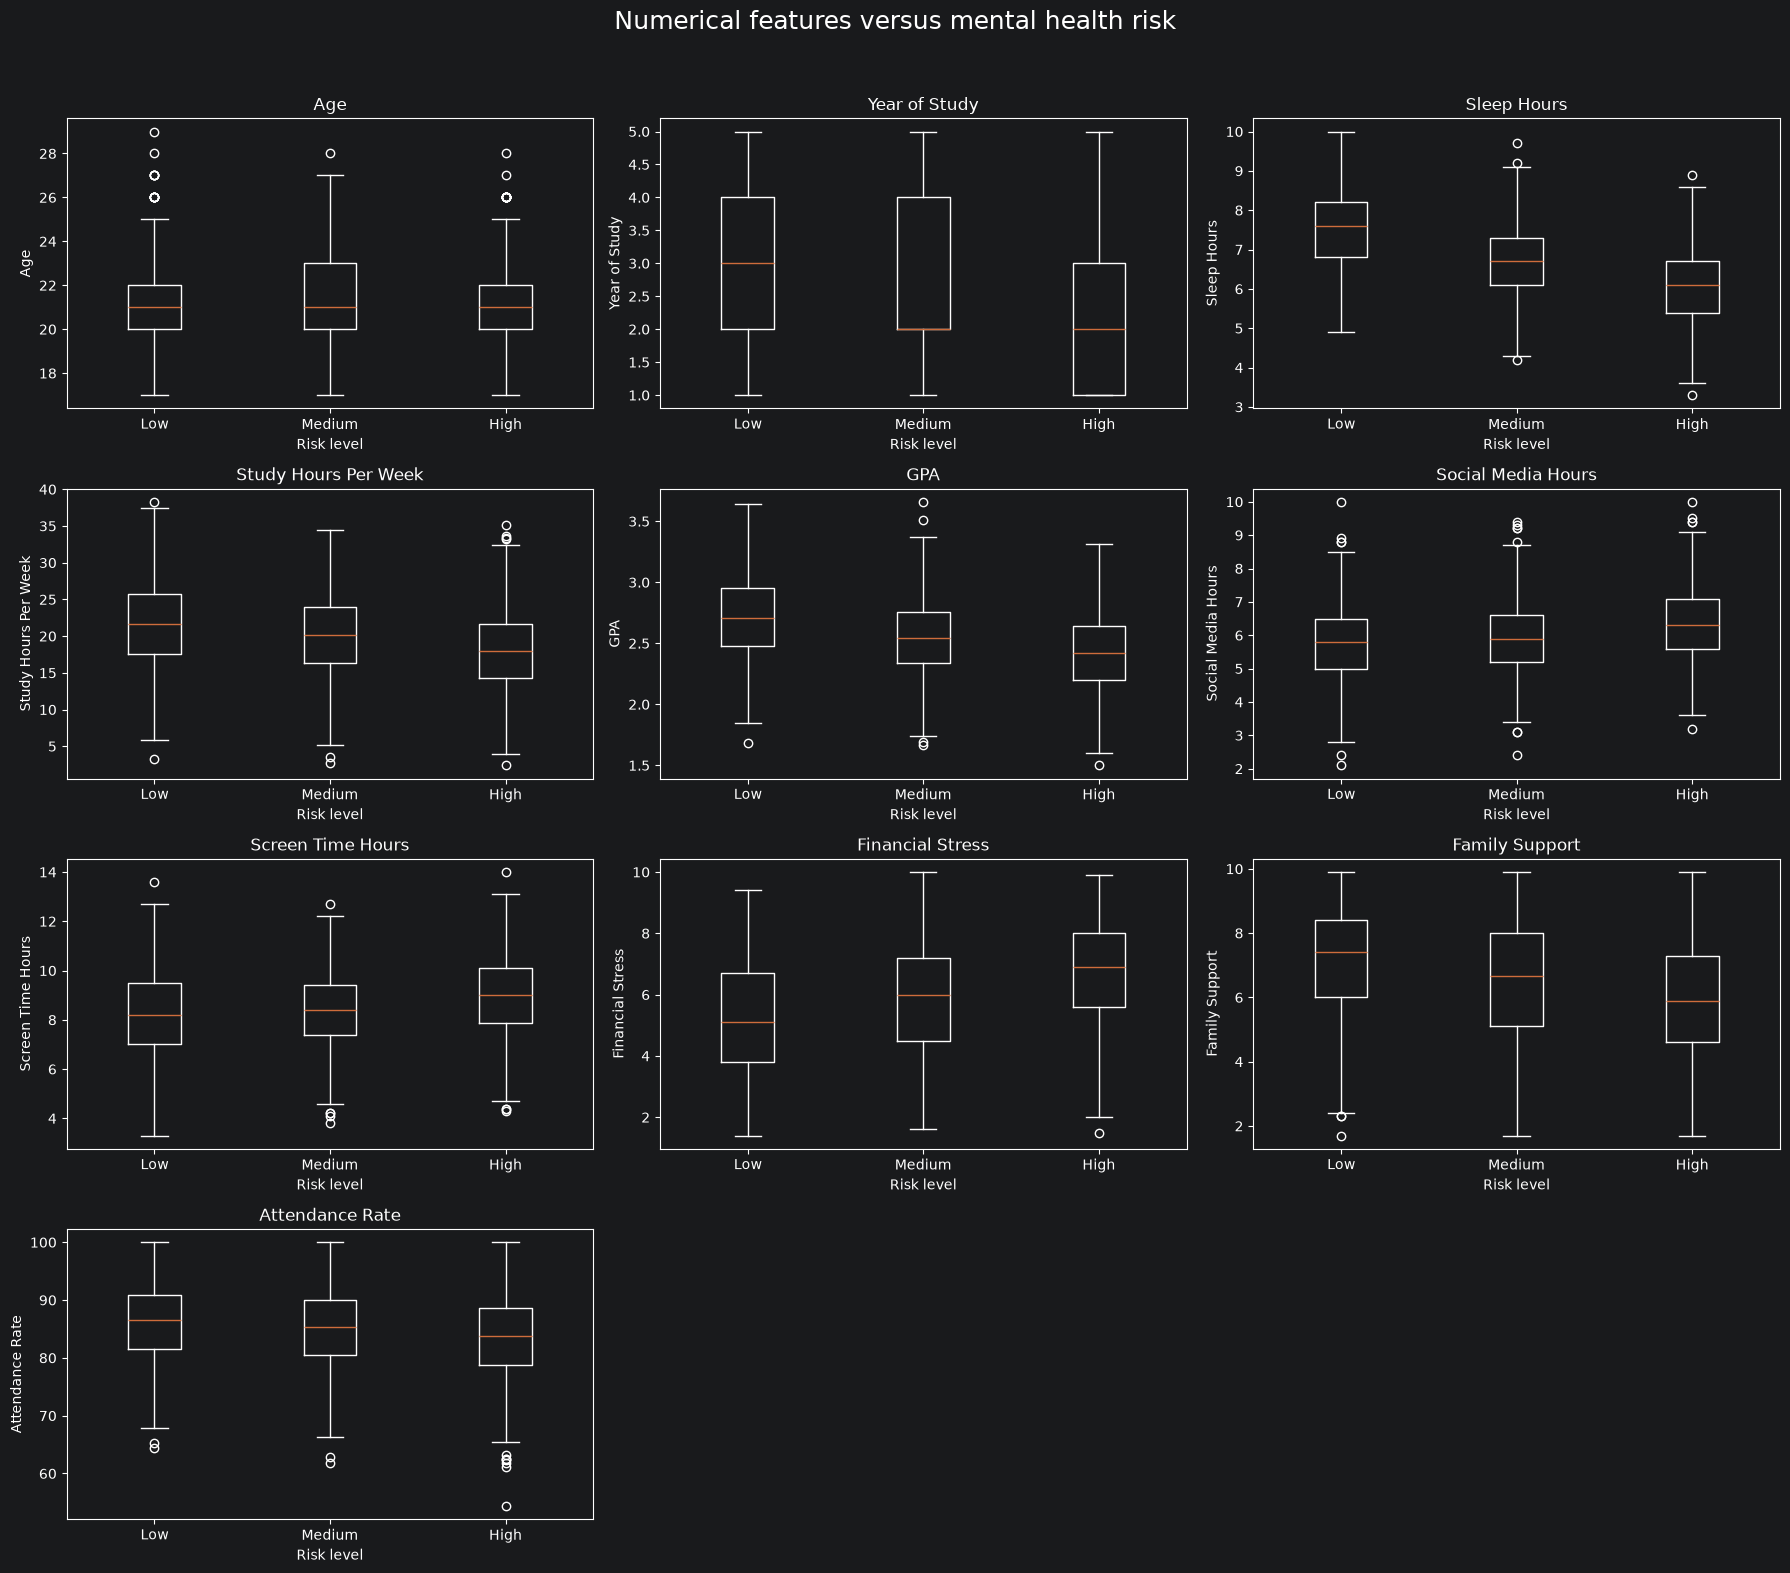

In [59]:
risk_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
fig.suptitle("Numerical features versus mental health risk", fontsize=18)
for i, column in enumerate(numerical_columns):
    ax = axes.flat[i]
    groups = [
        df.loc[df["Mental_Health_Risk"] == risk, column].dropna()
        for risk in risk_order
    ]
    ax.boxplot(groups, tick_labels=risk_order)
    ax.set_title(column.replace("_", " "))
    ax.set_xlabel("Risk level")
    ax.set_ylabel(column.replace("_", " "))
for i in range(len(numerical_columns), axes.size):
    fig.delaxes(axes.flat[i])
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, "numerical_features_by_risk")
plt.show()

### Interpretation of numerical features versus target

These box plots compare the median, middle 50%, and spread of each feature across Low, Medium, and High risk. Values read from the axes are approximate. The conclusions describe associations in this synthetic dataset, rather than causal effects.

**Age:** The three groups have nearly identical medians around **21 years**, and their boxes overlap substantially. There is little visible separation between risk levels. **Conclusion:** Age shows no clear association with risk level.

**Year_of_Study:** Low-risk records tend toward later academic years, while High-risk records tend toward earlier years. The median moves from approximately **3** for Low risk to **2** for Medium and High risk, although the boxes overlap considerably. **Conclusion:** Earlier study years are associated with higher risk levels.

**Sleep_Hours:** Median sleep decreases from roughly **7.6 to 6.7 to 6.1 hours** as risk increases. The middle 50% also shifts toward shorter sleep, showing that the pattern involves the central observations rather than only a few extreme values. Some overlap remains between groups. **Conclusion:** Shorter sleep is associated with higher risk levels.

**Study_Hours_Per_Week:** Median study time decreases from approximately **22 to 20 to 18 hours per week** from Low to High risk. The boxes shift downward but still overlap substantially. **Conclusion:** Fewer weekly study hours are associated with higher risk levels.

**GPA:** Both the medians and the middle 50% shift downward as risk increases. Low-risk records generally have higher GPA values, while High-risk records tend toward lower values, with overlap between the groups. **Conclusion:** Lower GPA is associated with higher risk levels.

**Social_Media_Hours:** Typical daily usage increases slightly across the risk levels, with the High-risk group having the highest median. The boxes overlap strongly, so many records across different risk levels have similar usage. **Conclusion:** More social media usage is associated with higher risk levels.

**Screen_Time_Hours:** Medians increase gradually from Low to High risk, and the High-risk box sits somewhat higher. The middle 50% overlaps substantially across all three groups. **Conclusion:** More daily screen time is associated with higher risk levels.

**Financial_Stress:** Median stress scores increase clearly from approximately **5 to 6 to 7** as risk rises. The middle 50% also shifts toward higher scores, although the groups still overlap. **Conclusion:** Higher financial stress is associated with higher risk levels.

**Family_Support:** The medians and boxes shift downward from Low to High risk. The Low-risk group tends to report greater support, while the High-risk group tends to report less support. There is still substantial overlap. **Conclusion:** Lower family support is associated with higher risk levels.

**Attendance_Rate:** Median attendance decreases slightly as risk increases. The High-risk group tends toward lower attendance, but the boxes overlap heavily and their spreads are similar. **Conclusion:** Lower attendance is associated with higher risk levels.

**Overall:** Sleep hours, financial stress, and family support show some of the clearest associations with risk level. Age shows little visible association.


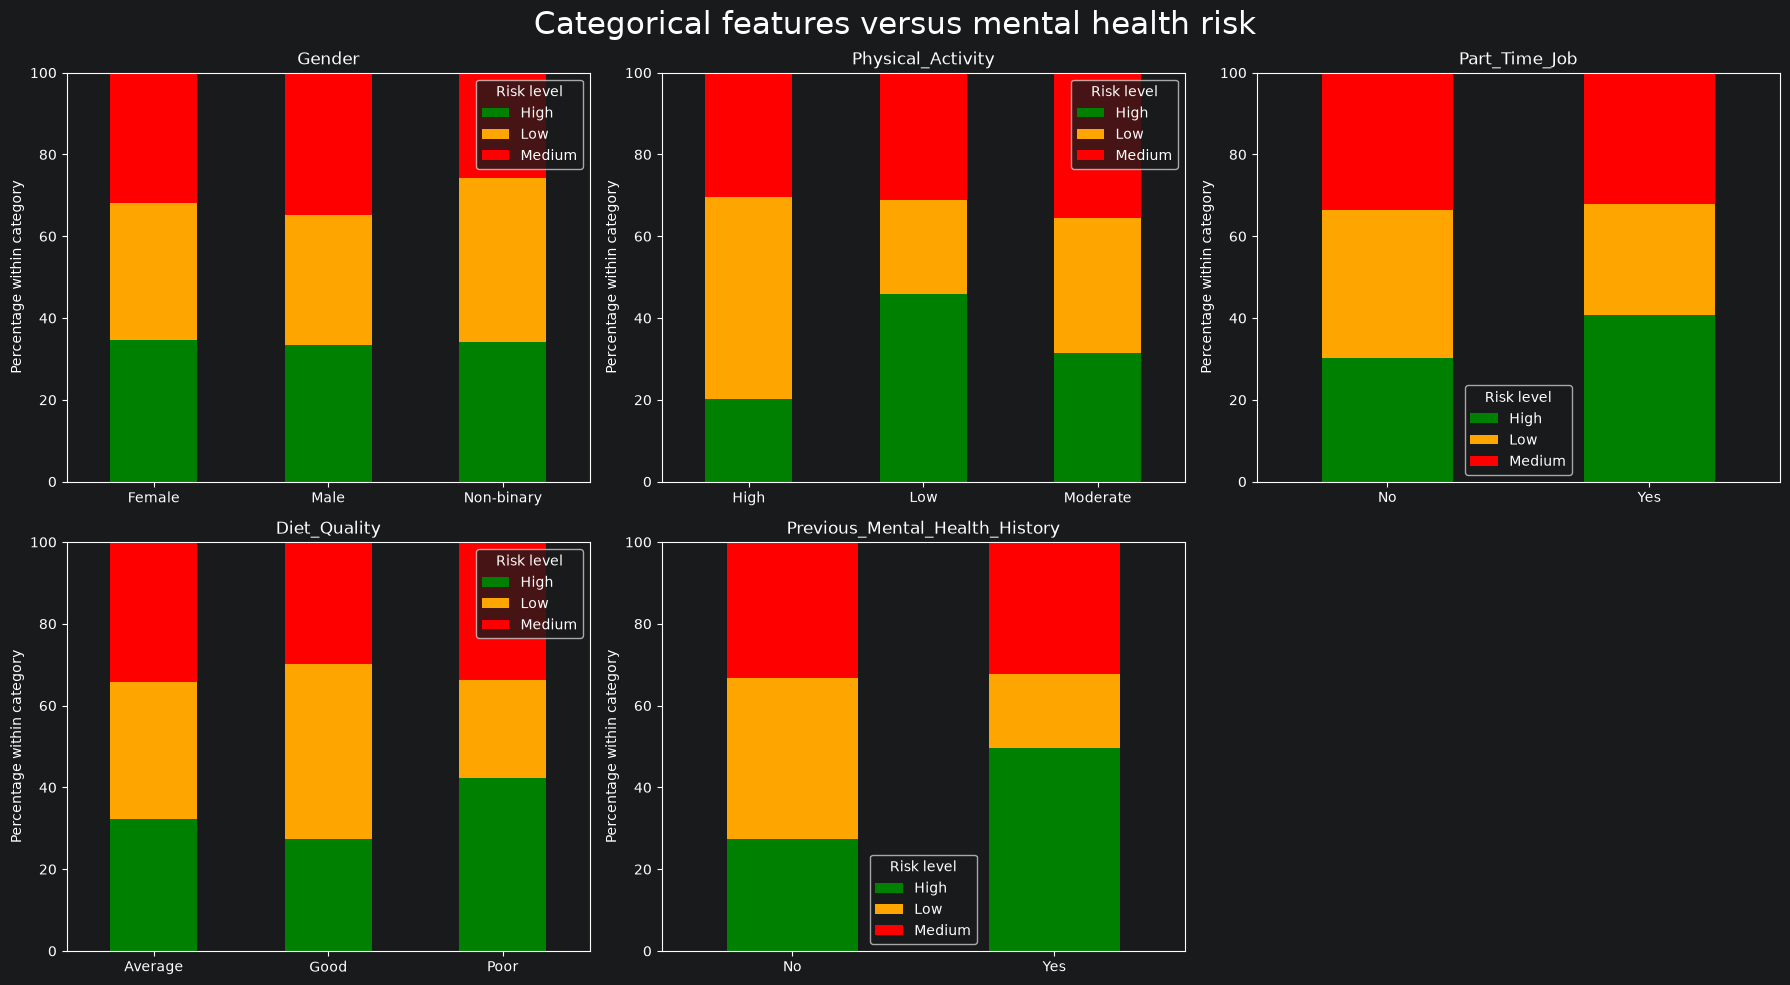

In [66]:
risk_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Categorical features versus mental health risk", fontsize=22)

for i, column in enumerate(categorical_columns):
    ax = axes.flat[i]
    proportions = pd.crosstab(
        df[column], df["Mental_Health_Risk"], normalize="index"
    ) * 100
    proportions = proportions.reindex(columns=risk_order, fill_value=0)
    proportions = pd.crosstab(
        df[column], df["Mental_Health_Risk"], normalize="index"
    ) * 100


    proportions.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["green", "orange", "red"],
        rot=0,
    )
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Percentage within category")
    ax.set_ylim(0, 100)
    ax.legend(title="Risk level")

for i in range(len(categorical_columns), axes.size):
    fig.delaxes(axes.flat[i])

fig.tight_layout()
save_figure(fig, "categorical_features_by_risk")
plt.show()


## Relationships and redundancy
Record observations and justify decisions here after selecting the dataset.

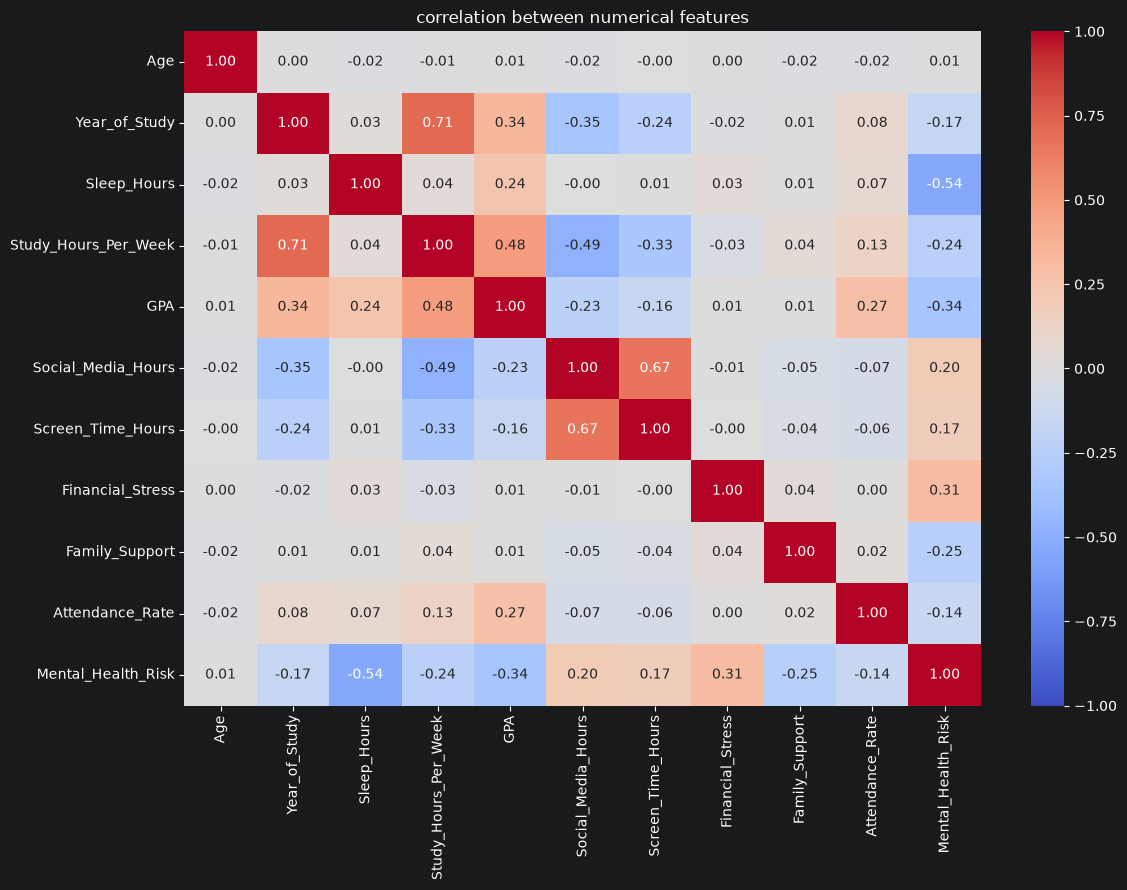

In [81]:
import seaborn as sns

risk_map = {
    "Low" : 0,
    "Medium" : 1,
    "High" : 2
}

corr_data = df[numerical_columns].copy()
corr_data["Mental_Health_Risk"] = df["Mental_Health_Risk"].map(risk_map)
correlations = corr_data.corr(method = "spearman")
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("correlation between numerical features")
plt.tight_layout()
save_figure(fig, "spearman_correlation_heatmap")
plt.show()

### Interpretation of the correlation matrix

| Feature pair | Correlation | Interpretation |
|---|---|---|
| Year_of_Study ↔ Study_Hours_Per_Week | +0.70 | The strongest positive relationship in the chart. Students in later years tend to study more hours per week. |
| Social_Media_Hours ↔ Screen_Time_Hours | +0.68 | Students who report more social media hours also tend to report more screen time. These features may capture some of the same behavior. |
| Study_Hours_Per_Week ↔ Social_Media_Hours | −0.50 | The strongest negative relationship in the chart. Students who report more study hours tend to report fewer social media hours. |
| Study_Hours_Per_Week ↔ GPA | +0.49 | Students who report more study hours tend to have higher GPAs. The chart alone can’t establish whether studying more causes a higher GPA. |
| GPA ↔ Attendance_Rate and Sleep_Hours | +0.29, +0.25 | Higher attendance and longer sleep each show a weaker positive relationship with GPA. |


## Findings and justified preprocessing decisions
Record observations and justify decisions here after selecting the dataset.

now as a conlusion lets dive into the decision we are gonna take for the preprocessing ,
starting with seven conlumns that contains missing values , we are gonna use mean for symmetric data  cuz there is no influential extremes values , and median for data with skewness distrubiton or may use knn ,

for categorical features :
gender we gonna use on hot
physical activity ordinal encoding
part time job binary encoding
diet quality oridinal encoding
previous mental helath history binary encoding .
mental health risk label encoding ,
student id is an identifier so we will delete it ,






outliers handling :
for all columns the ouliters detected by iqr rule are kinda valid,
for the contradictions rows betweens social media hours and screen hours we cant correct them cuz we dont know which measurements is correct so we will make them na values instead to imput them after.
